# Question 5 — Predicting Daily Social Media Usage Hours

**Research question:** Can a user's average daily social-media usage hours be predicted from their usage characteristics?

This notebook examines whether `Avg_Daily_Usage_Hours` can be predicted using behavioral characteristics of social-media use:

- `Daily_Unlocks`
- `Most_Used_Platform`
- `Purpose_Of_Use`

The target variable is continuous, so this is a **supervised regression problem**.

The analysis is designed to answer two related questions:

1. Do the available usage characteristics contain enough information to predict daily usage hours better than a simple baseline?
2. How much predictive value is added by the platform and purpose-of-use variables beyond the number of daily unlocks?

To answer the second question, four feature sets are compared:

| Feature set | Predictors |
|---|---|
| A — Unlocks only | `Daily_Unlocks` |
| B — Unlocks + Platform | `Daily_Unlocks`, `Most_Used_Platform` |
| C — Unlocks + Purpose | `Daily_Unlocks`, `Purpose_Of_Use` |
| D — Full usage profile | `Daily_Unlocks`, `Most_Used_Platform`, `Purpose_Of_Use` |

Several regression approaches are evaluated because they represent different possible relationships in the data:

- **Ridge Regression** — a regularized linear relationship
- **Random Forest Regressor** — nonlinear relationships and interactions
- **K-Nearest Neighbors Regressor** — similarity between users
- **Support Vector Regression** — a smooth nonlinear relationship

A `DummyRegressor` is also included as a baseline. It does not learn relationships between the predictors and the target; it predicts the mean usage hours observed in the training data. A machine-learning model is useful only if it performs meaningfully better than this baseline.

Model and feature-set selection will be based on cross-validation results from the training data. The final test set will remain unseen until the best approach has been selected.

The main evaluation metric is **RMSE**, supported by **MAE** and **R²**:

- **RMSE** gives greater weight to large prediction errors.
- **MAE** expresses the average prediction error directly in hours.
- **R²** measures the proportion of variation in usage hours explained by the model.

Because the dataset is observational and self-reported, the results describe predictive associations and should not be interpreted as causal effects.

## 0. Setup & Data Loading


In [1]:
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV
)

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance


# Reproducibility
RANDOM_STATE = 42

# Plotting style
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (9, 5)


# Cleaned dataset created by the first data-exploration notebook
DATA_PATH = "../dataset/student_social_media_cleaned.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. "
        "Run data_exploration/01_data_overview_and_distributions.ipynb first."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (4998, 13)


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 1. Experimental Design

The data were split into 80% training and 20% testing sets.

Four feature sets were compared:

| Feature set | Predictors |
|---|---|
| A | `Daily_Unlocks` |
| B | `Daily_Unlocks` + `Most_Used_Platform` |
| C | `Daily_Unlocks` + `Purpose_Of_Use` |
| D | All three predictors |

Models were compared using five-fold cross-validation on the training set.

The main metric is RMSE, supported by MAE and R².  
The test set is used only after selecting the best model.

In [2]:
# Target and feature sets
TARGET = "Avg_Daily_Usage_Hours"

FEATURE_SETS = {
    "A - Unlocks only": ["Daily_Unlocks"],
    "B - Unlocks + Platform": ["Daily_Unlocks","Most_Used_Platform"],
    "C - Unlocks + Purpose": ["Daily_Unlocks","Purpose_Of_Use"],
    "D - Full usage profile": ["Daily_Unlocks","Most_Used_Platform","Purpose_Of_Use"]
}

required_columns = [TARGET,"Daily_Unlocks","Most_Used_Platform","Purpose_Of_Use"]

analysis_df = df[required_columns].copy()

assert analysis_df.isna().sum().sum() == 0, \
    "Missing values were found in the modeling variables."
# Use the same observations in every experiment
train_df, test_df = train_test_split(
    analysis_df,
    test_size=0.20,
    random_state=RANDOM_STATE
)
y_train = train_df[TARGET]
y_test = test_df[TARGET]

# Cross-validation
cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)
SCORING = {"MAE": "neg_mean_absolute_error","RMSE": "neg_root_mean_squared_error","R2": "r2"}
print(f"Training rows: {len(train_df):,}")
print(f"Test rows: {len(test_df):,}")
print(f"Training target mean: {y_train.mean():.2f} hours")
print(f"Test target mean: {y_test.mean():.2f} hours")

Training rows: 3,998
Test rows: 1,000
Training target mean: 5.08 hours
Test target mean: 5.07 hours


## 2. Data Preprocessing

Numerical variables are standardized, while categorical variables are converted using one-hot encoding.

All preprocessing is performed inside the model pipeline to prevent data leakage.

In [3]:
def create_preprocessor(feature_columns):
    numeric_features = [
        column for column in feature_columns
        if column == "Daily_Unlocks"
    ]

    categorical_features = [
        column for column in feature_columns
        if column in ["Most_Used_Platform", "Purpose_Of_Use"]
    ]

    transformers = []

    if numeric_features:
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])

        transformers.append(
            ("numeric", numeric_pipeline, numeric_features)
        )

    if categorical_features:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ])

        transformers.append(
            ("categorical", categorical_pipeline, categorical_features)
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

## 3. Baseline Model

A `DummyRegressor` is used as a baseline. It predicts the mean usage hours without learning from the predictors.

A useful model should achieve lower MAE and RMSE than this baseline.

In [4]:
# Dummy baseline - predicts the training mean
dummy_model = DummyRegressor(strategy="mean")

dummy_cv = cross_validate(
    dummy_model,
    train_df[["Daily_Unlocks"]],
    y_train,
    cv=cv_strategy,
    scoring=SCORING,
    n_jobs=-1
)

baseline_results = pd.DataFrame({
    "Model": ["DummyRegressor"],
    "CV MAE": [-dummy_cv["test_MAE"].mean()],
    "CV RMSE": [-dummy_cv["test_RMSE"].mean()],
    "CV RMSE SD": [dummy_cv["test_RMSE"].std()],
    "CV R2": [dummy_cv["test_R2"].mean()]
})

print(f"Baseline prediction: {y_train.mean():.2f} hours")
display(baseline_results.round(3))

Baseline prediction: 5.08 hours


,Model,CV MAE,CV RMSE,CV RMSE SD,CV R2
0,DummyRegressor,1.374,1.646,0.019,-0.001


## 4. Incremental Feature Comparison

Ridge Regression is used to compare the four feature sets.

This shows whether platform and purpose-of-use add predictive value beyond daily unlocks.

In [5]:
ridge_results = []

for feature_set_name, feature_columns in FEATURE_SETS.items():

    ridge_pipeline = Pipeline([
        ("preprocessor", create_preprocessor(feature_columns)),
        ("model", Ridge(alpha=1.0, solver="lsqr"))
    ])

    cv_results = cross_validate(
        ridge_pipeline,
        train_df[feature_columns],
        y_train,
        cv=cv_strategy,
        scoring=SCORING,
        n_jobs=-1
    )

    ridge_results.append({
        "Feature set": feature_set_name,
        "CV MAE": -cv_results["test_MAE"].mean(),
        "CV RMSE": -cv_results["test_RMSE"].mean(),
        "CV RMSE SD": cv_results["test_RMSE"].std(),
        "CV R2": cv_results["test_R2"].mean()
    })


ridge_feature_results = pd.DataFrame(ridge_results)

baseline_rmse = baseline_results.loc[0, "CV RMSE"]

ridge_feature_results["RMSE improvement vs baseline (%)"] = (
    (baseline_rmse - ridge_feature_results["CV RMSE"])
    / baseline_rmse * 100
)

ridge_feature_results = ridge_feature_results.sort_values(
    "CV RMSE"
).reset_index(drop=True)

display(ridge_feature_results.round(3))

,Feature set,CV MAE,CV RMSE,CV RMSE SD,CV R2,RMSE improvement vs baseline (%)
0,B - Unlocks + Platform,0.387,0.461,0.002,0.922,72.010
1,D - Full usage profile,0.387,0.461,0.002,0.921,71.999
2,A - Unlocks only,0.388,0.462,0.002,0.921,71.956
3,C - Unlocks + Purpose,0.389,0.462,0.002,0.921,71.926


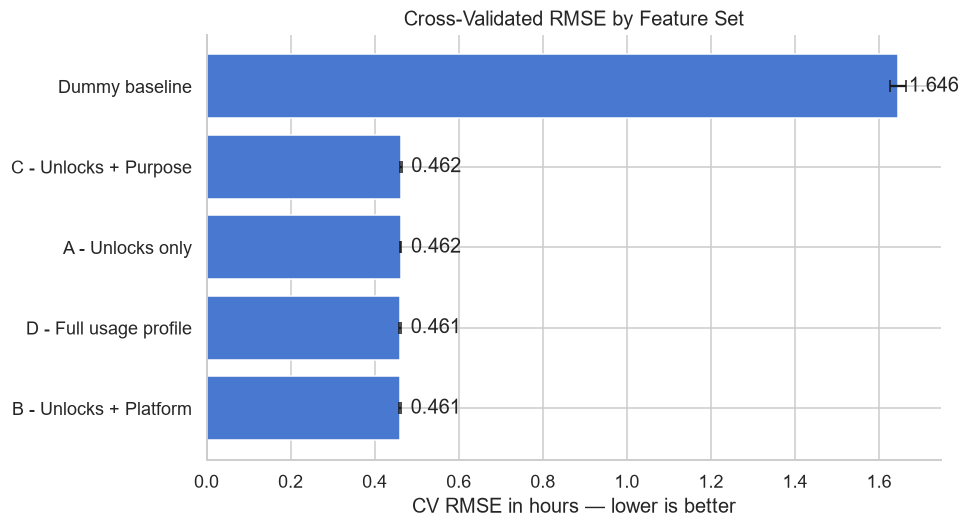

In [6]:
plot_data = pd.concat([
    pd.DataFrame({
        "Configuration": ["Dummy baseline"],
        "CV RMSE": [baseline_results.loc[0, "CV RMSE"]],
        "CV RMSE SD": [baseline_results.loc[0, "CV RMSE SD"]]
    }),

    ridge_feature_results[
        ["Feature set", "CV RMSE", "CV RMSE SD"]
    ].rename(columns={
        "Feature set": "Configuration"
    })
], ignore_index=True)

plot_data = plot_data.sort_values(
    "CV RMSE",
    ascending=False
).reset_index(drop=True)


fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    plot_data["Configuration"],
    plot_data["CV RMSE"],
    xerr=plot_data["CV RMSE SD"],
    capsize=4
)

ax.invert_yaxis()

ax.set_title("Cross-Validated RMSE by Feature Set")
ax.set_xlabel("CV RMSE in hours — lower is better")
ax.set_ylabel("")

for bar, value in zip(bars, plot_data["CV RMSE"]):
    ax.text(
        value + 0.025,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center"
    )

sns.despine()
plt.tight_layout()
plt.show()

The number of daily unlocks provided almost all the predictive information, reducing RMSE by approximately 72% compared with the baseline.

Adding platform produced only a negligible improvement, while purpose of use did not improve prediction. Therefore, feature set B was selected as the numerically best set, although its advantage over unlocks alone was very small.

## 5. Model Comparison

Using the best feature set, four regression models were compared with the same cross-validation folds.

In [7]:
selected_features = FEATURE_SETS["B - Unlocks + Platform"]

models = {
    "Ridge": Ridge(alpha=1.0, solver="lsqr"),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=10,
        weights="distance"
    ),

    "SVR": SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    )
}

model_results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", create_preprocessor(selected_features)),
        ("model", model)
    ])

    cv_results = cross_validate(
        pipeline,
        train_df[selected_features],
        y_train,
        cv=cv_strategy,
        scoring=SCORING,
        n_jobs=-1
    )

    model_results.append({
        "Model": model_name,
        "CV MAE": -cv_results["test_MAE"].mean(),
        "CV RMSE": -cv_results["test_RMSE"].mean(),
        "CV RMSE SD": cv_results["test_RMSE"].std(),
        "CV R2": cv_results["test_R2"].mean()
    })


model_comparison = (
    pd.DataFrame(model_results)
    .sort_values("CV RMSE")
    .reset_index(drop=True)
)

display(model_comparison.round(3))

,Model,CV MAE,CV RMSE,CV RMSE SD,CV R2
0,Random Forest,0.318,0.408,0.009,0.938
1,KNN,0.318,0.412,0.009,0.937
2,SVR,0.376,0.455,0.004,0.923
3,Ridge,0.387,0.461,0.002,0.922


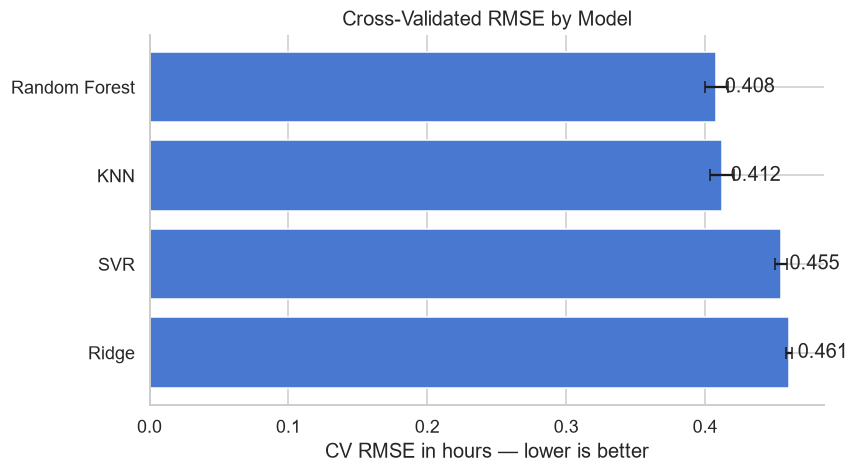

In [8]:
plot_models = model_comparison.sort_values(
    "CV RMSE",
    ascending=False
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    plot_models["Model"],
    plot_models["CV RMSE"],
    xerr=plot_models["CV RMSE SD"],
    capsize=4
)

ax.set_title("Cross-Validated RMSE by Model")
ax.set_xlabel("CV RMSE in hours — lower is better")
ax.set_ylabel("")

for bar, value in zip(bars, plot_models["CV RMSE"]):
    ax.text(
        value + 0.006,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center"
    )

sns.despine()
plt.tight_layout()
plt.show()

Random Forest achieved the lowest average RMSE, although its error range overlapped with KNN. Therefore, both models showed similar predictive performance, with Random Forest retaining a small numerical advantage.

## 6. Hyperparameter Tuning

Random Forest and KNN were tuned using cross-validation on the training set.  
The configuration with the lowest RMSE was selected.

In [9]:
tuning_models = {
    "Random Forest": {
        "model": RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "parameters": {
            "model__n_estimators": [200, 400],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 2, 4]
        }
    },

    "KNN": {
        "model": KNeighborsRegressor(),
        "parameters": {
            "model__n_neighbors": [5, 10, 15, 20],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    }
}

tuning_results = []
best_estimators = {}

for model_name, configuration in tuning_models.items():

    pipeline = Pipeline([
        ("preprocessor", create_preprocessor(selected_features)),
        ("model", configuration["model"])
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=configuration["parameters"],
        scoring="neg_root_mean_squared_error",
        cv=cv_strategy,
        n_jobs=-1
    )

    search.fit(
        train_df[selected_features],
        y_train
    )

    best_estimators[model_name] = search.best_estimator_

    tuning_results.append({
        "Model": model_name,
        "Best CV RMSE": -search.best_score_
    })

tuning_results = (
    pd.DataFrame(tuning_results)
    .sort_values("Best CV RMSE")
    .reset_index(drop=True)
)

display(tuning_results)

,Model,Best CV RMSE
0,Random Forest,0.408201
1,KNN,0.411521


Random Forest remained the best-performing model after hyperparameter tuning, with a slightly lower RMSE than KNN.

However, tuning produced almost no additional improvement, indicating that the initial model was already close to its optimal configuration.

## 7. Final Test Evaluation

The tuned Random Forest model was evaluated once on the unseen test set and compared with the baseline.

In [10]:
# Select the best tuned model
best_model_name = tuning_results.iloc[0]["Model"]
final_model = best_estimators[best_model_name]

# Fit on the complete training set
final_model.fit(
    train_df[selected_features],
    y_train
)

# Final test predictions
test_predictions = final_model.predict(
    test_df[selected_features]
)


# Baseline predictions on the test set
final_dummy = DummyRegressor(strategy="mean")

final_dummy.fit(
    train_df[selected_features],
    y_train
)

baseline_predictions = final_dummy.predict(
    test_df[selected_features]
)


def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


baseline_test_metrics = calculate_metrics(
    y_test,
    baseline_predictions
)

final_test_metrics = calculate_metrics(
    y_test,
    test_predictions
)


test_results = pd.DataFrame([
    {
        "Model": "Dummy baseline",
        **baseline_test_metrics
    },
    {
        "Model": best_model_name,
        **final_test_metrics
    }
])

baseline_test_rmse = baseline_test_metrics["RMSE"]

test_results["RMSE improvement vs baseline (%)"] = (
    (baseline_test_rmse - test_results["RMSE"])
    / baseline_test_rmse * 100
)

display(test_results.round(3))

,Model,MAE,RMSE,R2,RMSE improvement vs baseline (%)
0,Dummy baseline,1.430,1.687,-0.000,0.000
1,Random Forest,0.315,0.403,0.943,76.094


Random Forest substantially outperformed the baseline on the unseen test set.

The model achieved an MAE of 0.315 hours and explained 94.3% of the variation in daily usage hours. Its RMSE was approximately 76% lower than the baseline, indicating strong generalization to unseen observations.

### Actual vs. Predicted Usage Hours

Predicted values are compared with the actual test values. Predictions closer to the diagonal line indicate greater accuracy.

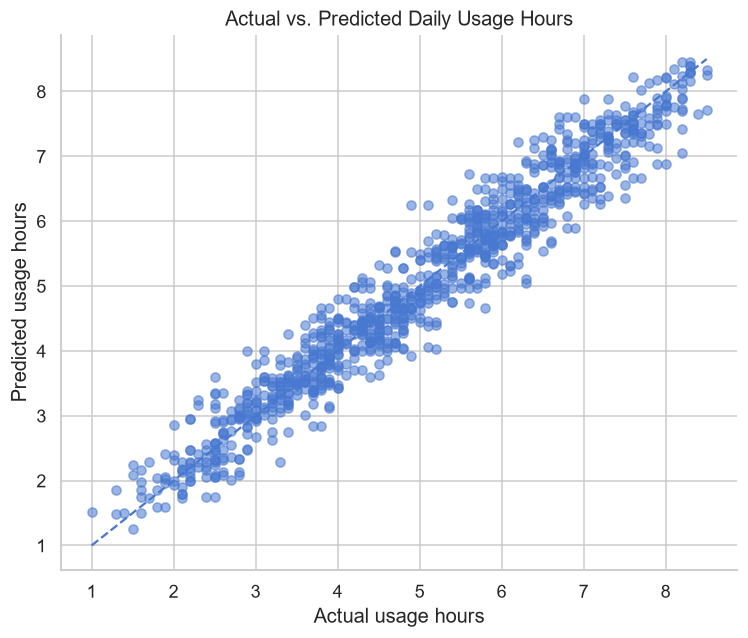

In [11]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.55
)

minimum = min(y_test.min(), test_predictions.min())
maximum = max(y_test.max(), test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual usage hours")
plt.ylabel("Predicted usage hours")
plt.title("Actual vs. Predicted Daily Usage Hours")

sns.despine()
plt.tight_layout()
plt.show()

Most predictions were close to the diagonal line, confirming the model's strong test performance.

A slight regression-to-the-mean pattern was observed: very low usage values were sometimes overestimated, while very high values were slightly underestimated.

## 8. Conclusion

Daily social-media usage hours could be predicted accurately from the available usage characteristics.

Random Forest achieved the best test performance:

- MAE: 0.315 hours
- RMSE: 0.403 hours
- R²: 0.943
- 76.1% lower RMSE than the baseline

Most of the predictive ability came from `Daily_Unlocks`. Platform added little additional information, while purpose of use did not improve prediction.

Therefore, the number of daily unlocks is sufficient to predict usage hours with high accuracy in this dataset. These results represent predictive associations and do not establish causality.